# Faster R-CNN on COCO 2017 (Kaggle)

This notebook trains and evaluates a Faster R-CNN model on the COCO 2017 dataset at:
`/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017`

It is designed to run on Kaggle GPU with optional dataset subsampling for faster experiments.

In [1]:
# Optional dependency installs (safe to run on Kaggle)
!pip -q install pycocotools torchmetrics

In [2]:
import os
import random
import time
from dataclasses import dataclass

import numpy as np
import torch
import torchvision
from PIL import Image
from pycocotools.coco import COCO
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection.mean_ap import MeanAveragePrecision
import matplotlib.pyplot as plt
import matplotlib.patches as patches

print('Torch:', torch.__version__)
print('Torchvision:', torchvision.__version__)

Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128


In [3]:
@dataclass
class CFG:
    DATA_ROOT: str = '/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017'
    TRAIN_IMAGES: str = 'train2017'
    VAL_IMAGES: str = 'val2017'
    TRAIN_ANN: str = 'annotations/instances_train2017.json'
    VAL_ANN: str = 'annotations/instances_val2017.json'

    IMAGE_SIZE: int = 640
    BATCH_SIZE: int = 4
    NUM_WORKERS: int = 2
    EPOCHS: int = 5
    LR: float = 5e-4
    WEIGHT_DECAY: float = 1e-4

    # None means use full split without capping image count
    MAX_TRAIN_IMAGES: int | None = None
    MAX_VAL_IMAGES: int | None = None

    SEED: int = 42
    OUTPUT_DIR: str = '/kaggle/working'

cfg = CFG()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
print('Using device:', device)

Using device: cuda


In [4]:
import shutil
import glob

# Optional: copy an existing checkpoint from Kaggle input into working dir.
# Set this to either a specific .pth file or a folder containing fasterrcnn_epoch_XX.pth files.
INPUT_CHECKPOINT_PATH = '/kaggle/input/models/piyushjain051204/asterrcnn-epoch-03/pytorch/default/1/fasterrcnn_epoch_03.pth'
# Example file: '/kaggle/input/my-checkpoints/fasterrcnn_epoch_03.pth'
# Example folder: '/kaggle/input/my-checkpoints'


def _extract_epoch_num(path):
    name = os.path.basename(path)
    if name.startswith('fasterrcnn_epoch_') and name.endswith('.pth'):
        try:
            return int(name.split('_')[-1].split('.')[0])
        except ValueError:
            return -1
    return -1


if INPUT_CHECKPOINT_PATH:
    candidate_paths = []

    if os.path.isfile(INPUT_CHECKPOINT_PATH):
        candidate_paths = [INPUT_CHECKPOINT_PATH]
    elif os.path.isdir(INPUT_CHECKPOINT_PATH):
        candidate_paths = glob.glob(os.path.join(INPUT_CHECKPOINT_PATH, 'fasterrcnn_epoch_*.pth'))
    else:
        print(f'Input checkpoint path not found: {INPUT_CHECKPOINT_PATH}')

    if candidate_paths:
        candidate_paths = sorted(candidate_paths, key=_extract_epoch_num)
        src_ckpt = candidate_paths[-1]
        dst_ckpt = os.path.join(cfg.OUTPUT_DIR, os.path.basename(src_ckpt))

        if os.path.abspath(src_ckpt) != os.path.abspath(dst_ckpt):
            shutil.copy2(src_ckpt, dst_ckpt)
            print(f'Copied checkpoint to working dir: {dst_ckpt}')
        else:
            print(f'Checkpoint already in working dir: {dst_ckpt}')
    else:
        print('No matching fasterrcnn_epoch_*.pth checkpoint found at input path.')
else:
    print('INPUT_CHECKPOINT_PATH is None, skipping input checkpoint copy step.')

Copied checkpoint to working dir: /kaggle/working/fasterrcnn_epoch_03.pth


In [5]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(cfg.SEED)

In [6]:
def get_train_transforms(image, target, image_size=640):
    # Simple resize + tensor conversion for stable baseline training
    image = torchvision.transforms.functional.resize(image, (image_size, image_size))
    image = torchvision.transforms.functional.to_tensor(image)

    w_scale = image_size / target['orig_width']
    h_scale = image_size / target['orig_height']
    boxes = target['boxes'].clone()
    boxes[:, [0, 2]] *= w_scale
    boxes[:, [1, 3]] *= h_scale

    target['boxes'] = boxes
    return image, target


def get_val_transforms(image, target, image_size=640):
    image = torchvision.transforms.functional.resize(image, (image_size, image_size))
    image = torchvision.transforms.functional.to_tensor(image)

    w_scale = image_size / target['orig_width']
    h_scale = image_size / target['orig_height']
    boxes = target['boxes'].clone()
    boxes[:, [0, 2]] *= w_scale
    boxes[:, [1, 3]] *= h_scale

    target['boxes'] = boxes
    return image, target

In [7]:
class CocoDetectionForTorchvision(Dataset):
    def __init__(self, root, ann_file, transforms=None, max_images=None):
        self.root = root
        self.coco = COCO(ann_file)
        self.transforms = transforms

        img_ids = self.coco.getImgIds()
        img_ids = [img_id for img_id in img_ids if len(self.coco.getAnnIds(imgIds=img_id, iscrowd=None)) > 0]

        if max_images is not None:
            img_ids = img_ids[:max_images]

        self.img_ids = img_ids

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_info = self.coco.loadImgs(img_id)[0]
        path = os.path.join(self.root, img_info['file_name'])

        image = Image.open(path).convert('RGB')
        ann_ids = self.coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        for ann in anns:
            x, y, w, h = ann['bbox']
            if w <= 1 or h <= 1:
                continue
            boxes.append([x, y, x + w, y + h])
            labels.append(ann['category_id'])
            areas.append(ann['area'])
            iscrowd.append(ann.get('iscrowd', 0))

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            areas = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)
            areas = torch.tensor(areas, dtype=torch.float32)
            iscrowd = torch.tensor(iscrowd, dtype=torch.int64)

        target = {
            'boxes': boxes,
            'labels': labels,
            'image_id': torch.tensor([img_id], dtype=torch.int64),
            'area': areas,
            'iscrowd': iscrowd,
            'orig_width': img_info['width'],
            'orig_height': img_info['height'],
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)

        target.pop('orig_width')
        target.pop('orig_height')

        return image, target

In [8]:
def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

train_dataset = CocoDetectionForTorchvision(
    root=os.path.join(cfg.DATA_ROOT, cfg.TRAIN_IMAGES),
    ann_file=os.path.join(cfg.DATA_ROOT, cfg.TRAIN_ANN),
    transforms=lambda img, tgt: get_train_transforms(img, tgt, cfg.IMAGE_SIZE),
    max_images=cfg.MAX_TRAIN_IMAGES,
)

val_dataset = CocoDetectionForTorchvision(
    root=os.path.join(cfg.DATA_ROOT, cfg.VAL_IMAGES),
    ann_file=os.path.join(cfg.DATA_ROOT, cfg.VAL_ANN),
    transforms=lambda img, tgt: get_val_transforms(img, tgt, cfg.IMAGE_SIZE),
    max_images=cfg.MAX_VAL_IMAGES,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

print('Train images:', len(train_dataset))
print('Val images:', len(val_dataset))

loading annotations into memory...
Done (t=14.78s)
creating index...
index created!
loading annotations into memory...
Done (t=0.89s)
creating index...
index created!
Train images: 117266
Val images: 4952


In [9]:
# COCO pretrained Faster R-CNN (ResNet50-FPN)
weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=weights)
model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

print('Model initialized.')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 193MB/s]


Model initialized.


In [10]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scaler, device):
    model.train()
    running_loss = 0.0

    start = time.time()
    for images, targets in tqdm(loader, desc='Training', leave=True):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        scaler.scale(losses).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += losses.item()

    epoch_loss = running_loss / max(len(loader), 1)
    elapsed = time.time() - start
    return epoch_loss, elapsed


@torch.inference_mode()
def evaluate_map(model, loader, device):
    model.eval()
    metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', class_metrics=True)

    for images, targets in tqdm(loader, desc='Validation', leave=True):
        images = [img.to(device) for img in images]
        outputs = model(images)

        preds = []
        gts = []
        for out, tgt in zip(outputs, targets):
            preds.append({
                'boxes': out['boxes'].detach().cpu(),
                'scores': out['scores'].detach().cpu(),
                'labels': out['labels'].detach().cpu(),
            })
            gts.append({
                'boxes': tgt['boxes'].detach().cpu(),
                'labels': tgt['labels'].detach().cpu(),
            })

        metric.update(preds, gts)

    return metric.compute()

In [11]:
history = {
    'train_loss': [],
    'map': [],
    'map_50': [],
    'map_75': [],
    'train_time_s': [],
    'eval_time_s': [],
}

best_map50 = -1.0
best_path = os.path.join(cfg.OUTPUT_DIR, 'fasterrcnn_best.pth')
epoch_ckpt_paths = []
last_eval_metrics = None
start_epoch = 0
resume_path = None

existing_checkpoints = []
for file_name in os.listdir(cfg.OUTPUT_DIR):
    if file_name.startswith('fasterrcnn_epoch_') and file_name.endswith('.pth'):
        try:
            epoch_number = int(file_name.split('_')[-1].split('.')[0])
            existing_checkpoints.append((epoch_number, os.path.join(cfg.OUTPUT_DIR, file_name)))
        except ValueError:
            pass

if existing_checkpoints:
    existing_checkpoints.sort(key=lambda item: item[0])
    _, resume_path = existing_checkpoints[-1]
    checkpoint = torch.load(resume_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    if 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    if 'scaler_state_dict' in checkpoint:
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
    history = checkpoint.get('history', history)
    best_map50 = float(checkpoint.get('map_50', best_map50))
    last_eval_metrics = checkpoint.get('last_eval_metrics', None)
    start_epoch = int(checkpoint.get('epoch', 0))
    print(f'Resuming from {resume_path} at epoch {start_epoch + 1}')
else:
    print('No epoch checkpoint found. Starting from scratch.')

if start_epoch >= cfg.EPOCHS:
    print(f'Checkpoint is already at epoch {start_epoch}; nothing left to train.')

for epoch in range(start_epoch, cfg.EPOCHS):
    t_train_start = time.perf_counter()
    train_loss, train_time = train_one_epoch(model, train_loader, optimizer, scaler, device)
    train_time = time.perf_counter() - t_train_start

    t_eval_start = time.perf_counter()
    metrics = evaluate_map(model, val_loader, device)
    eval_time = time.perf_counter() - t_eval_start

    scheduler.step()

    map_val = float(metrics['map'])
    map50_val = float(metrics['map_50'])
    map75_val = float(metrics['map_75'])
    last_eval_metrics = metrics

    history['train_loss'].append(train_loss)
    history['map'].append(map_val)
    history['map_50'].append(map50_val)
    history['map_75'].append(map75_val)
    history['train_time_s'].append(train_time)
    history['eval_time_s'].append(eval_time)

    checkpoint = {
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'cfg': cfg.__dict__,
        'history': history,
        'last_eval_metrics': metrics,
        'train_loss': train_loss,
        'map': map_val,
        'map_50': map50_val,
        'map_75': map75_val,
        'train_time_s': train_time,
        'eval_time_s': eval_time,
    }

    # Save every epoch checkpoint
    epoch_path = os.path.join(cfg.OUTPUT_DIR, f'fasterrcnn_epoch_{epoch + 1:02d}.pth')
    print('=> Saving checkpoint')
    torch.save(checkpoint, epoch_path)
    epoch_ckpt_paths.append(epoch_path)

    if map50_val > best_map50:
        best_map50 = map50_val
        torch.save(checkpoint, best_path)

    print(
        f"Epoch {epoch + 1}/{cfg.EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"mAP: {map_val:.4f} | mAP@0.50: {map50_val:.4f} | mAP@0.75: {map75_val:.4f} | "
        f"Train: {train_time:.1f}s | Eval: {eval_time:.1f}s | "
        f"Saved: {epoch_path}"
    )

print('Best checkpoint saved to:', best_path)
print('Per-epoch checkpoints:')
for p in epoch_ckpt_paths:
    print(' -', p)

Resuming from /kaggle/working/fasterrcnn_epoch_03.pth at epoch 4


Training:   0%|          | 0/29317 [00:00<?, ?it/s]

Validation:   0%|          | 0/1238 [00:00<?, ?it/s]

=> Saving checkpoint
Epoch 4/5 | Train Loss: 0.7702 | mAP: 0.1365 | mAP@0.50: 0.2580 | mAP@0.75: 0.1297 | Train: 12388.6s | Eval: 569.3s | Saved: /kaggle/working/fasterrcnn_epoch_04.pth


Training:   0%|          | 0/29317 [00:00<?, ?it/s]

Validation:   0%|          | 0/1238 [00:00<?, ?it/s]

=> Saving checkpoint
Epoch 5/5 | Train Loss: 0.7537 | mAP: 0.1475 | mAP@0.50: 0.2741 | mAP@0.75: 0.1425 | Train: 12405.8s | Eval: 566.1s | Saved: /kaggle/working/fasterrcnn_epoch_05.pth
Best checkpoint saved to: /kaggle/working/fasterrcnn_best.pth
Per-epoch checkpoints:
 - /kaggle/working/fasterrcnn_epoch_04.pth
 - /kaggle/working/fasterrcnn_epoch_05.pth


/tmp/ipykernel_24/2161543807.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


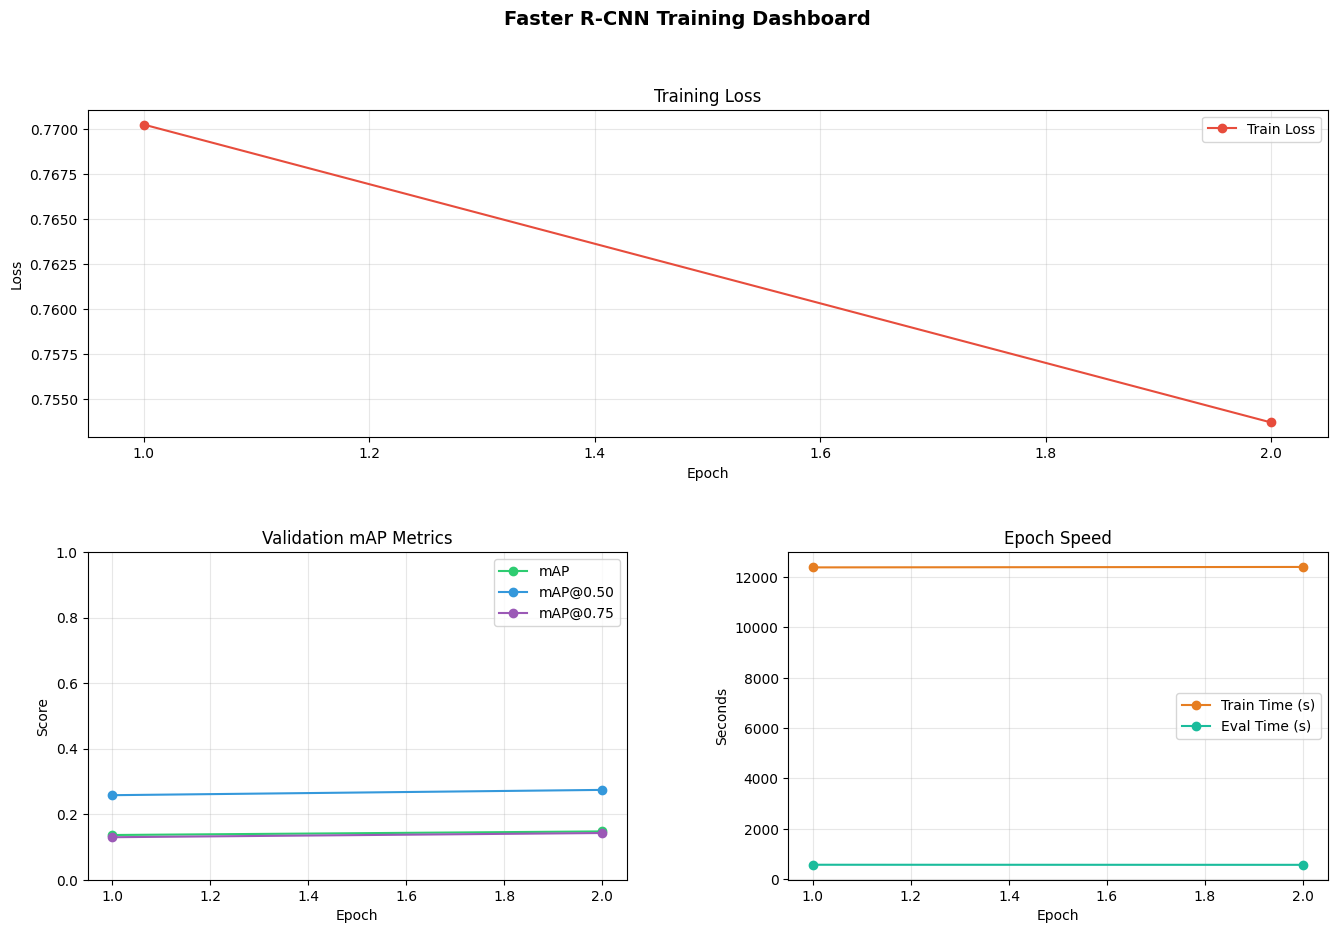

In [12]:
# ============================================
# EXTRA VISUALIZATIONS (YOLO-like diagnostics)
# ============================================

from collections import Counter

def plot_training_dashboard(history):
    epochs = np.arange(1, len(history['train_loss']) + 1)
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(epochs, history['train_loss'], label='Train Loss', marker='o', color='#e74c3c')
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(epochs, history['map'], marker='o', label='mAP', color='#2ecc71')
    ax2.plot(epochs, history['map_50'], marker='o', label='mAP@0.50', color='#3498db')
    ax2.plot(epochs, history['map_75'], marker='o', label='mAP@0.75', color='#9b59b6')
    ax2.set_ylim(0, 1)
    ax2.set_title('Validation mAP Metrics')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Score')
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    ax3 = fig.add_subplot(gs[1, 1])
    ax3.plot(epochs, history['train_time_s'], marker='o', label='Train Time (s)', color='#e67e22')
    ax3.plot(epochs, history['eval_time_s'], marker='o', label='Eval Time (s)', color='#1abc9c')
    ax3.set_title('Epoch Speed')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Seconds')
    ax3.grid(True, alpha=0.3)
    ax3.legend()

    plt.suptitle('Faster R-CNN Training Dashboard', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


def plot_rpn_anchor_boxes(model, image_size=640):
    sizes = model.rpn.anchor_generator.sizes
    aspect_ratios = model.rpn.anchor_generator.aspect_ratios

    fig, axes = plt.subplots(1, len(sizes), figsize=(4 * len(sizes), 4))
    if len(sizes) == 1:
        axes = [axes]

    for level, ax in enumerate(axes):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.25)
        ax.set_facecolor('#f8f9fa')

        level_sizes = sizes[level]
        level_ratios = aspect_ratios[level]
        colors = plt.cm.tab10(np.linspace(0, 1, len(level_sizes) * len(level_ratios)))
        c_idx = 0

        for s in level_sizes:
            for ar in level_ratios:
                w = (s * (1.0 / np.sqrt(ar))) / image_size
                h = (s * np.sqrt(ar)) / image_size
                x0 = 0.5 - w / 2
                y0 = 0.5 - h / 2
                rect = patches.Rectangle(
                    (x0, y0), w, h, linewidth=1.8, edgecolor=colors[c_idx],
                    facecolor=colors[c_idx], alpha=0.2
                )
                ax.add_patch(rect)
                c_idx += 1

        ax.set_title(f'FPN Level {level + 1}\nSizes={level_sizes}, Ratios={level_ratios}')
        ax.set_xlabel('Relative Width')
        ax.set_ylabel('Relative Height')

    plt.suptitle('Faster R-CNN RPN Anchor Boxes', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


def plot_coco_class_distribution(dataset, top_k=30, max_images=10000):
    coco = dataset.coco
    counts = Counter()
    img_ids = dataset.img_ids[:max_images]

    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anns = coco.loadAnns(ann_ids)
        for ann in anns:
            counts[ann['category_id']] += 1

    sorted_counts = counts.most_common(top_k)
    if not sorted_counts:
        print('No annotations found for class distribution plot.')
        return

    cat_id_to_name = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}
    names = [cat_id_to_name.get(cid, str(cid)) for cid, _ in sorted_counts]
    values = [v for _, v in sorted_counts]

    fig, ax = plt.subplots(figsize=(16, 6))
    bars = ax.barh(names[::-1], values[::-1], color=plt.cm.viridis(np.linspace(0.2, 0.9, len(names))))
    ax.set_title(f'COCO Class Distribution (Top {top_k})', fontweight='bold')
    ax.set_xlabel('Count')
    ax.grid(axis='x', alpha=0.3)

    for bar, count in zip(bars, values[::-1]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f' {int(count)}', va='center', fontsize=8)

    plt.tight_layout()
    plt.show()


def plot_bbox_size_distribution(dataset, max_images=10000):
    coco = dataset.coco
    all_w, all_h = [], []
    img_ids = dataset.img_ids[:max_images]

    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anns = coco.loadAnns(ann_ids)
        img_info = coco.loadImgs(img_id)[0]
        iw, ih = max(img_info['width'], 1), max(img_info['height'], 1)

        for ann in anns:
            x, y, w, h = ann['bbox']
            if w > 1 and h > 1:
                all_w.append(w / iw)
                all_h.append(h / ih)

    if len(all_w) == 0:
        print('No valid boxes found for bbox size distribution plot.')
        return

    all_w = np.array(all_w)
    all_h = np.array(all_h)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(all_w, all_h, s=4, alpha=0.25, color='#3498db')
    axes[0].set_title('Width vs Height (normalized)', fontweight='bold')
    axes[0].set_xlabel('Width')
    axes[0].set_ylabel('Height')
    axes[0].grid(True, alpha=0.3)

    axes[1].hist(all_w, bins=50, color='#e74c3c', edgecolor='white', linewidth=0.3)
    axes[1].set_title('BBox Width Distribution', fontweight='bold')
    axes[1].set_xlabel('Width')
    axes[1].grid(True, alpha=0.3)

    axes[2].hist(all_h, bins=50, color='#2ecc71', edgecolor='white', linewidth=0.3)
    axes[2].set_title('BBox Height Distribution', fontweight='bold')
    axes[2].set_xlabel('Height')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


@torch.inference_mode()
def plot_confidence_histogram(loader, model, device, num_batches=10):
    model.eval()
    all_scores = []

    for b_idx, (images, _) in enumerate(loader):
        if b_idx >= num_batches:
            break
        images = [img.to(device) for img in images]
        outputs = model(images)
        for out in outputs:
            if out['scores'].numel() > 0:
                all_scores.extend(out['scores'].detach().cpu().tolist())

    if len(all_scores) == 0:
        print('No prediction scores found to plot.')
        return

    all_scores = np.array(all_scores)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(all_scores, bins=100, color='#3498db', edgecolor='white', linewidth=0.3)
    axes[0].set_title('Prediction Confidence Distribution', fontweight='bold')
    axes[0].set_xlabel('Score')
    axes[0].set_ylabel('Count')
    axes[0].grid(True, alpha=0.3)

    thr = 0.5
    high = all_scores[all_scores >= thr]
    axes[1].hist(high, bins=50, color='#e74c3c', edgecolor='white', linewidth=0.3)
    axes[1].set_title(f'High Confidence (>= {thr}) | {len(high):,} boxes', fontweight='bold')
    axes[1].set_xlabel('Score')
    axes[1].set_ylabel('Count')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_per_class_map(metrics, class_names=None):
    if metrics is None or 'map_per_class' not in metrics or 'classes' not in metrics:
        print('Per-class mAP not available yet. Run evaluation first.')
        return

    classes = metrics['classes'].detach().cpu().numpy().astype(int)
    ap_values = metrics['map_per_class'].detach().cpu().numpy()

    valid = ap_values >= 0
    classes = classes[valid]
    ap_values = ap_values[valid]

    if len(ap_values) == 0:
        print('No valid per-class AP values to plot.')
        return

    if class_names is None:
        names = [str(c) for c in classes]
    else:
        names = [class_names[c] if c < len(class_names) else str(c) for c in classes]

    order = np.argsort(ap_values)[::-1]
    names = [names[i] for i in order]
    ap_values = ap_values[order]

    fig, ax = plt.subplots(figsize=(14, max(6, len(names) * 0.28)))
    bars = ax.barh(names[::-1], ap_values[::-1], color=plt.cm.RdYlGn(ap_values[::-1]))
    ax.set_xlim(0, 1)
    ax.set_title('Per-Class Average Precision', fontweight='bold')
    ax.set_xlabel('AP')
    ax.grid(axis='x', alpha=0.3)

    mean_ap = float(np.mean(ap_values))
    ax.axvline(mean_ap, color='navy', linestyle='--', linewidth=1.5, label=f'Mean AP={mean_ap:.3f}')
    ax.legend()

    for bar, ap in zip(bars, ap_values[::-1]):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, f'{ap:.3f}', va='center', fontsize=7)

    plt.tight_layout()
    plt.show()

# Quick dashboard call after training
plot_training_dashboard(history)

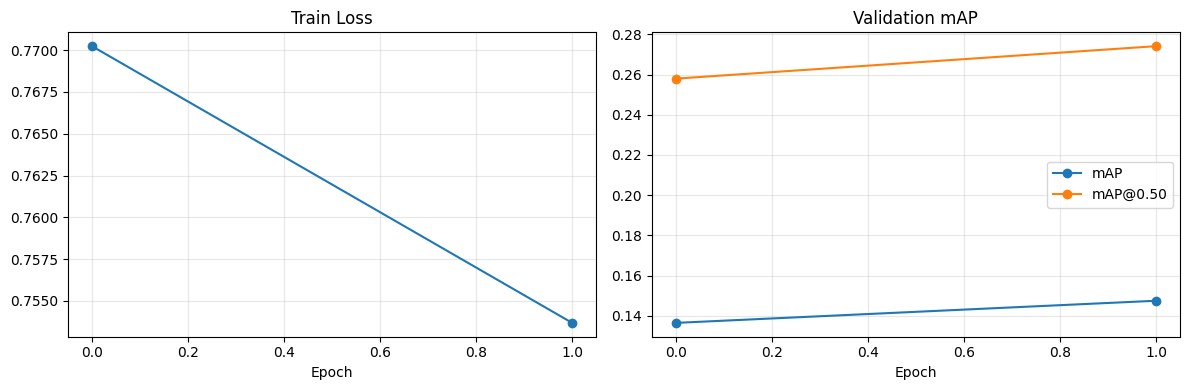

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], marker='o')
plt.title('Train Loss')
plt.xlabel('Epoch')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history['map'], marker='o', label='mAP')
plt.plot(history['map_50'], marker='o', label='mAP@0.50')
plt.title('Validation mAP')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

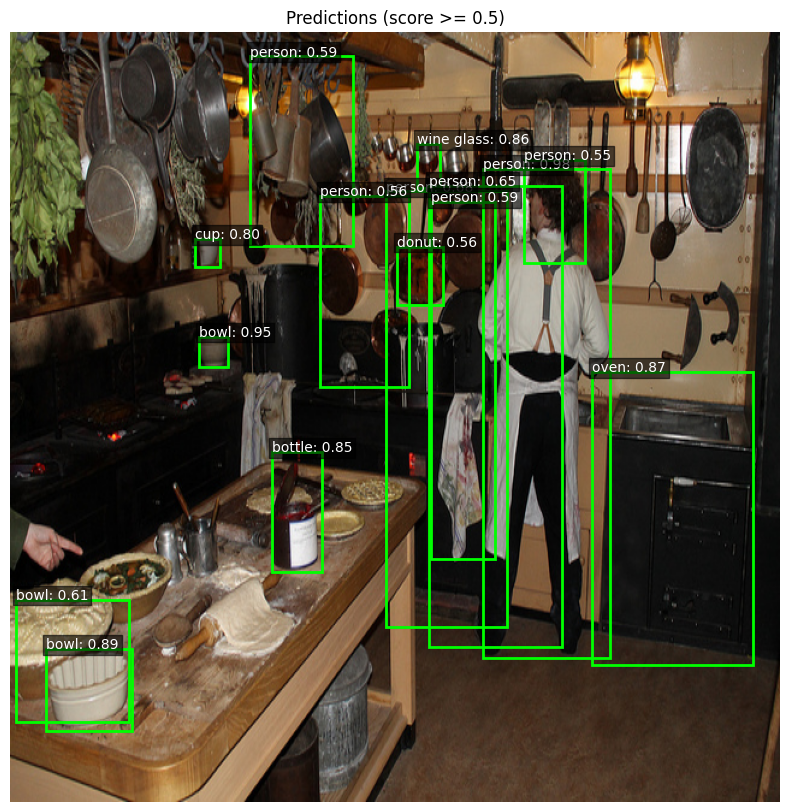

In [14]:
COCO_CLASSES = [
    '__background__','person','bicycle','car','motorcycle','airplane','bus','train','truck','boat',
    'traffic light','fire hydrant','N/A','stop sign','parking meter','bench','bird','cat','dog','horse',
    'sheep','cow','elephant','bear','zebra','giraffe','N/A','backpack','umbrella','N/A','N/A','handbag',
    'tie','suitcase','frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove',
    'skateboard','surfboard','tennis racket','bottle','N/A','wine glass','cup','fork','knife','spoon','bowl',
    'banana','apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut','cake','chair','couch',
    'potted plant','bed','N/A','dining table','N/A','N/A','toilet','N/A','tv','laptop','mouse','remote',
    'keyboard','cell phone','microwave','oven','toaster','sink','refrigerator','N/A','book','clock','vase',
    'scissors','teddy bear','hair drier','toothbrush'
]

def show_ground_truth(dataset, idx=0):
    image, target = dataset[idx]
    img_np = image.permute(1, 2, 0).cpu().numpy()

    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(img_np)

    for box, label in zip(target['boxes'], target['labels']):
        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.8, edgecolor='cyan', facecolor='none')
        ax.add_patch(rect)
        cls_name = COCO_CLASSES[int(label)] if int(label) < len(COCO_CLASSES) else str(int(label))
        ax.text(x1, y1, cls_name, color='white', bbox={'facecolor': 'black', 'alpha': 0.55, 'pad': 2})

    ax.set_title('Ground Truth Boxes')
    ax.axis('off')
    plt.show()


@torch.inference_mode()
def show_predictions(model, dataset, device, idx=0, score_thr=0.5):
    model.eval()
    image, target = dataset[idx]
    output = model([image.to(device)])[0]

    img_np = image.permute(1, 2, 0).cpu().numpy()
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(img_np)

    boxes = output['boxes'].cpu()
    scores = output['scores'].cpu()
    labels = output['labels'].cpu()

    keep = scores >= score_thr
    boxes = boxes[keep]
    scores = scores[keep]
    labels = labels[keep]

    for box, score, label in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
        cls_name = COCO_CLASSES[int(label)] if int(label) < len(COCO_CLASSES) else str(int(label))
        ax.text(x1, y1, f'{cls_name}: {float(score):.2f}', color='white',
                bbox={'facecolor': 'black', 'alpha': 0.6, 'pad': 2})

    ax.set_title(f'Predictions (score >= {score_thr})')
    ax.axis('off')
    plt.show()

# Example calls for YOLO-style graph suite:
# plot_rpn_anchor_boxes(model, image_size=cfg.IMAGE_SIZE)
# plot_coco_class_distribution(train_dataset, top_k=30)
# plot_bbox_size_distribution(train_dataset)
# plot_confidence_histogram(val_loader, model, device, num_batches=10)
# plot_per_class_map(last_eval_metrics, class_names=COCO_CLASSES)
# show_ground_truth(val_dataset, idx=0)
show_predictions(model, val_dataset, device, idx=0, score_thr=0.5)

## Notes for Kaggle Runs

- This notebook is configured for full COCO training and validation splits (no image caps).
- Training is configured for 5 epochs.
- Per-epoch checkpoints are saved as `/kaggle/working/fasterrcnn_epoch_XX.pth`.
- Best checkpoint is saved as `/kaggle/working/fasterrcnn_best.pth`.
- Use Kaggle `Save Version` to persist outputs.